In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [18]:
pip install pandas numpy matplotlib seaborn scikit-learn joblib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:

file_path = "/Users/bhagyeshannamareddy/Desktop/google-play-rating-prediction/data/raw/googleplaystore.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Dataset loaded successfully!
Rows    : 10841
Columns : 13


In [20]:

display(df.head(10))

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up
5,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,"50,000+",Free,0,Everyone,Art & Design,"March 26, 2017",1.0,2.3 and up
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,178,19M,"50,000+",Free,0,Everyone,Art & Design,"April 26, 2018",1.1,4.0.3 and up
7,Infinite Painter,ART_AND_DESIGN,4.1,36815,29M,"1,000,000+",Free,0,Everyone,Art & Design,"June 14, 2018",6.1.61.1,4.2 and up
8,Garden Coloring Book,ART_AND_DESIGN,4.4,13791,33M,"1,000,000+",Free,0,Everyone,Art & Design,"September 20, 2017",2.9.2,3.0 and up
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,121,3.1M,"10,000+",Free,0,Everyone,Art & Design;Creativity,"July 3, 2018",2.8,4.0.3 and up


In [21]:

print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])

Number of rows    : 10841
Number of columns : 13


In [22]:

print("Columns in dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(i, ".", column)

Columns in dataset:

1 . App
2 . Category
3 . Rating
4 . Reviews
5 . Size
6 . Installs
7 . Type
8 . Price
9 . Content Rating
10 . Genres
11 . Last Updated
12 . Current Ver
13 . Android Ver


In [23]:

print("Data Types:\n")

print(df.dtypes)

Data Types:

App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [25]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:

print("=" * 70)
print("PROBLEM DEFINITION")
print("=" * 70)

print("""
Problem Type     : Supervised Machine Learning
Task             : Regression
Target Variable  : Rating

Objective:
Predict the rating of a Google Play Store application
using information such as category, reviews, installs,
price, size, content rating, genre and version.

Models Used:
1. Linear Regression
2. Multiple Linear Regression
3. Polynomial Regression
4. Decision Tree Regression
5. Ridge Regression
""")

PROBLEM DEFINITION

Problem Type     : Supervised Machine Learning
Task             : Regression
Target Variable  : Rating

Objective:
Predict the rating of a Google Play Store application
using information such as category, reviews, installs,
price, size, content rating, genre and version.

Models Used:
1. Linear Regression
2. Multiple Linear Regression
3. Polynomial Regression
4. Decision Tree Regression
5. Ridge Regression



In [27]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_df = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing Percentage": missing_percentage.values
})

display(
    missing_df.sort_values(
        by="Missing Values",
        ascending=False
    )
)

,Column,Missing Values,Missing Percentage
2,Rating,1474,13.596532
11,Current Ver,8,0.073794
12,Android Ver,3,0.027673
6,Type,1,0.009224
8,Content Rating,1,0.009224
0,App,0,0.000000
1,Category,0,0.000000
3,Reviews,0,0.000000
4,Size,0,0.000000
5,Installs,0,0.000000


In [28]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 483


In [29]:

duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates removed.")
print("New dataset shape:", df.shape)

Duplicate rows found: 483
Duplicates removed.
New dataset shape: (10358, 13)


In [30]:
print("Rating minimum:", df["Rating"].min())
print("Rating maximum:", df["Rating"].max())

print("\nMissing Rating values:")
print(df["Rating"].isnull().sum())

print("\nRating statistics:")
print(df["Rating"].describe())

Rating minimum: 1.0
Rating maximum: 19.0

Missing Rating values:
1465

Rating statistics:
count    8893.000000
mean        4.189542
std         0.545452
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64


In [31]:
df = df[
    df["App"] != "Life Made WI-FI Touchscreen Photo Frame"
].copy()

df = df.dropna(
    subset=["Rating"]
).reset_index(drop=True)
df = df[
    df["Rating"].between(1, 5)
].reset_index(drop=True)

print("After target cleaning:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

After target cleaning:
Rows: 8892
Columns: 13


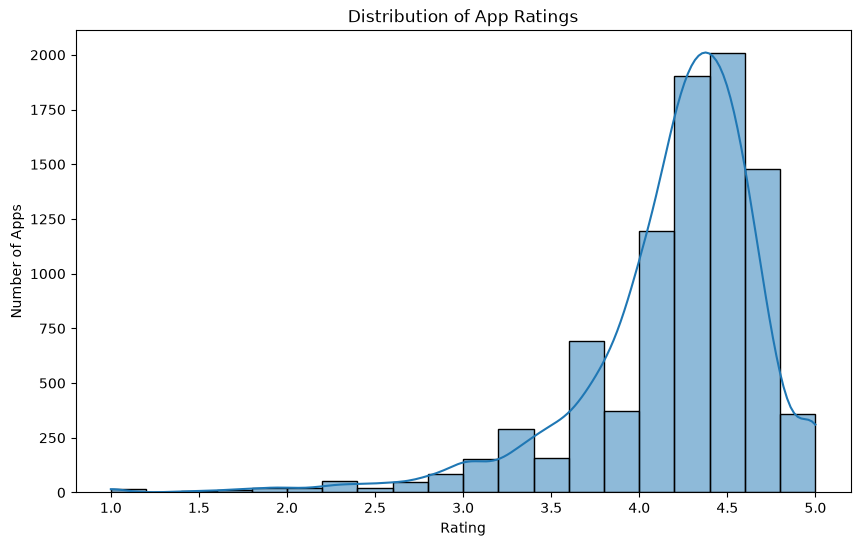

In [32]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Rating"],
    bins=20,
    kde=True
)

plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")

plt.show()

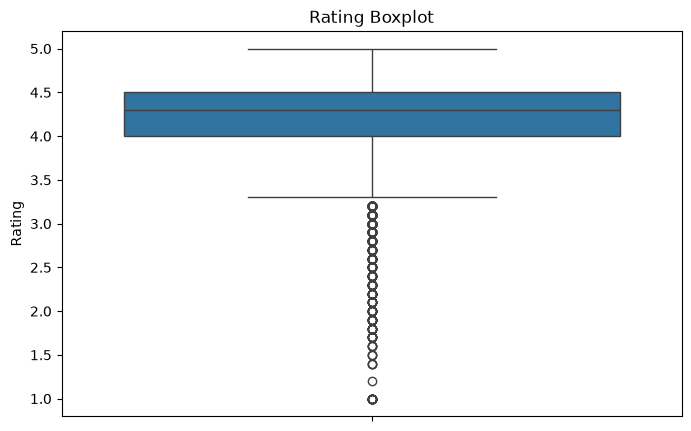

In [33]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df["Rating"]
)

plt.title("Rating Boxplot")
plt.ylabel("Rating")

plt.show()

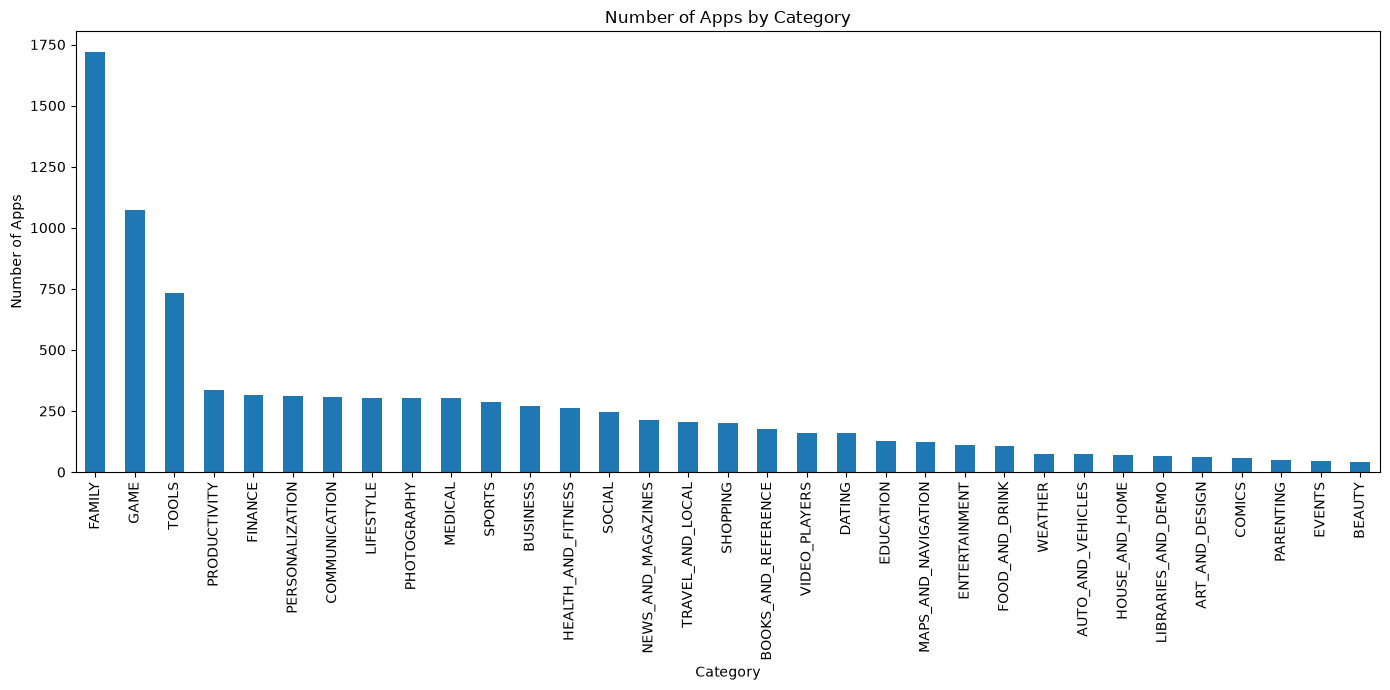

In [34]:

plt.figure(figsize=(14, 7))

df["Category"].value_counts().plot(
    kind="bar"
)

plt.title("Number of Apps by Category")
plt.xlabel("Category")
plt.ylabel("Number of Apps")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

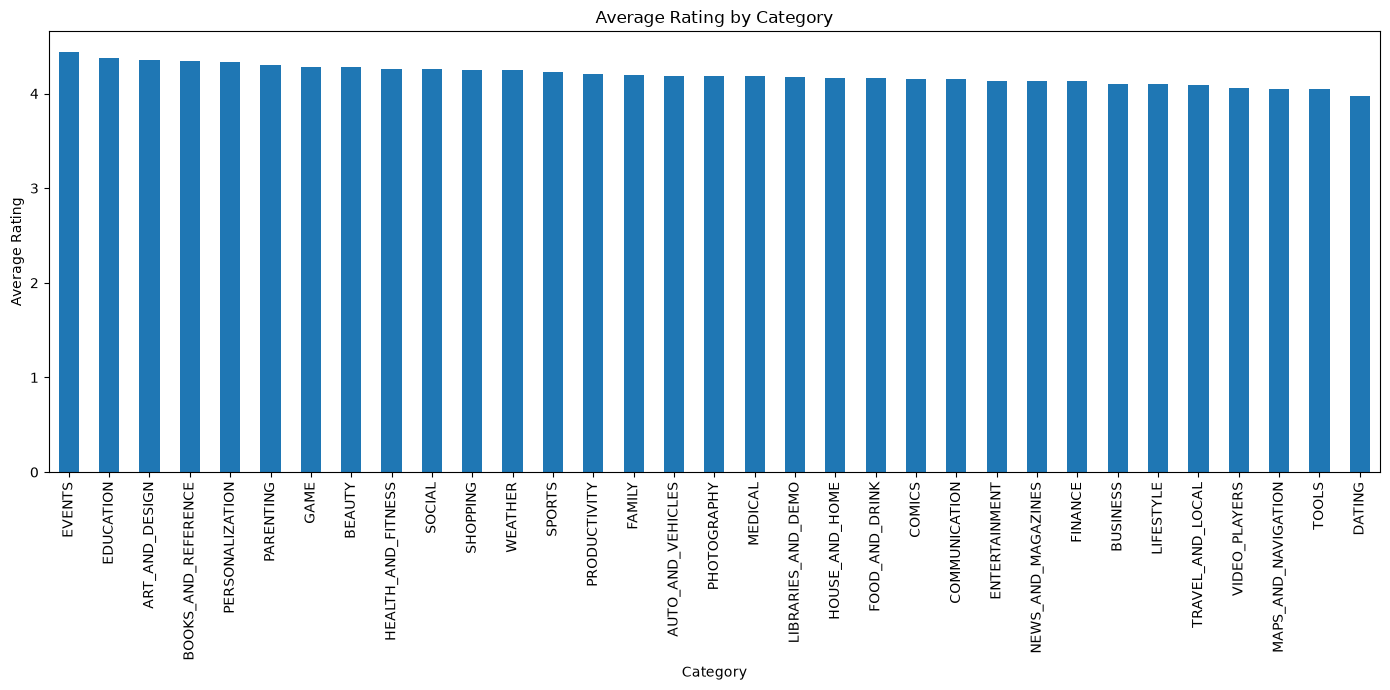

In [35]:

category_rating = (
    df.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 7))

category_rating.plot(
    kind="bar"
)

plt.title("Average Rating by Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

In [36]:

data = df.copy()

data["Reviews"] = pd.to_numeric(
    data["Reviews"],
    errors="coerce"
)

print("Reviews converted to numeric.")

Reviews converted to numeric.


In [37]:

data["Installs"] = (
    data["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

data["Installs"] = pd.to_numeric(
    data["Installs"],
    errors="coerce"
)

print("Installs converted to numeric.")

Installs converted to numeric.


In [38]:

data["Price"] = (
    data["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

data["Price"] = pd.to_numeric(
    data["Price"],
    errors="coerce"
)

print("Price converted to numeric.")

Price converted to numeric.


In [39]:

def convert_size(value):
    value = str(value).strip()

    if value.lower() == "nan":
        return np.nan

    if value.endswith("M"):
        return float(value[:-1])

    if value.endswith("k"):
        return float(value[:-1]) / 1024

    return np.nan


data["Size_MB"] = data["Size"].apply(convert_size)

display(
    data[["Size", "Size_MB"]].head(10)
)

,Size,Size_MB
0,19M,19.0
1,14M,14.0
2,8.7M,8.7
3,25M,25.0
4,2.8M,2.8
5,5.6M,5.6
6,19M,19.0
7,29M,29.0
8,33M,33.0
9,3.1M,3.1


In [40]:
data["Last Updated"] = pd.to_datetime(
    data["Last Updated"],
    errors="coerce"
)

data["Updated_Year"] = data["Last Updated"].dt.year
data["Updated_Month"] = data["Last Updated"].dt.month
data["Updated_Day"] = data["Last Updated"].dt.day

display(
    data[
        [
            "Last Updated",
            "Updated_Year",
            "Updated_Month",
            "Updated_Day"
        ]
    ].head()
)

,Last Updated,Updated_Year,Updated_Month,Updated_Day
0,2018-01-07,2018,1,7
1,2018-01-15,2018,1,15
2,2018-08-01,2018,8,1
3,2018-06-08,2018,6,8
4,2018-06-20,2018,6,20


In [41]:
data["Log_Reviews"] = np.log1p(
    data["Reviews"].clip(lower=0)
)

data["Log_Installs"] = np.log1p(
    data["Installs"].clip(lower=0)
)

data["Review_Rate"] = (
    data["Reviews"] /
    data["Installs"].replace(0, np.nan)
)

global_review_rate = (
    data["Reviews"] /
    data["Installs"].replace(0, np.nan)
).median()

smoothing_strength = 500

data["Smoothed_Review_Rate"] = (
    data["Reviews"] +
    smoothing_strength * global_review_rate
) / (
    data["Installs"] +
    smoothing_strength
)

data["Reviews_per_1000_Installs"] = (
    data["Smoothed_Review_Rate"] * 1000
)

data["Log_Size"] = np.log1p(
    data["Size_MB"].clip(lower=0)
)
data["Review_Rate"] = data["Review_Rate"].clip(0, 1)

print("Feature engineering completed!")

display(
    data[
        [
            "Reviews",
            "Installs",
            "Log_Reviews",
            "Log_Installs",
            "Review_Rate",
            "Smoothed_Review_Rate",
            "Reviews_per_1000_Installs",
            "Size_MB",
            "Log_Size"
        ]
    ].head()
)

Feature engineering completed!


,Reviews,Installs,Log_Reviews,Log_Installs,Review_Rate,Smoothed_Review_Rate,Reviews_per_1000_Installs,Size_MB,Log_Size
0,159,10000,5.075174,9.210440,0.015900,0.016058,16.058333,19.0,2.995732
1,967,500000,6.875232,13.122365,0.001934,0.001951,1.951274,14.0,2.708050
2,87510,5000000,11.379520,15.424949,0.017502,0.017502,17.502172,8.7,2.272126
3,215644,50000000,12.281389,17.727534,0.004313,0.004313,4.313029,25.0,3.258097
4,967,100000,6.875232,11.512935,0.009670,0.009718,9.717537,2.8,1.335001


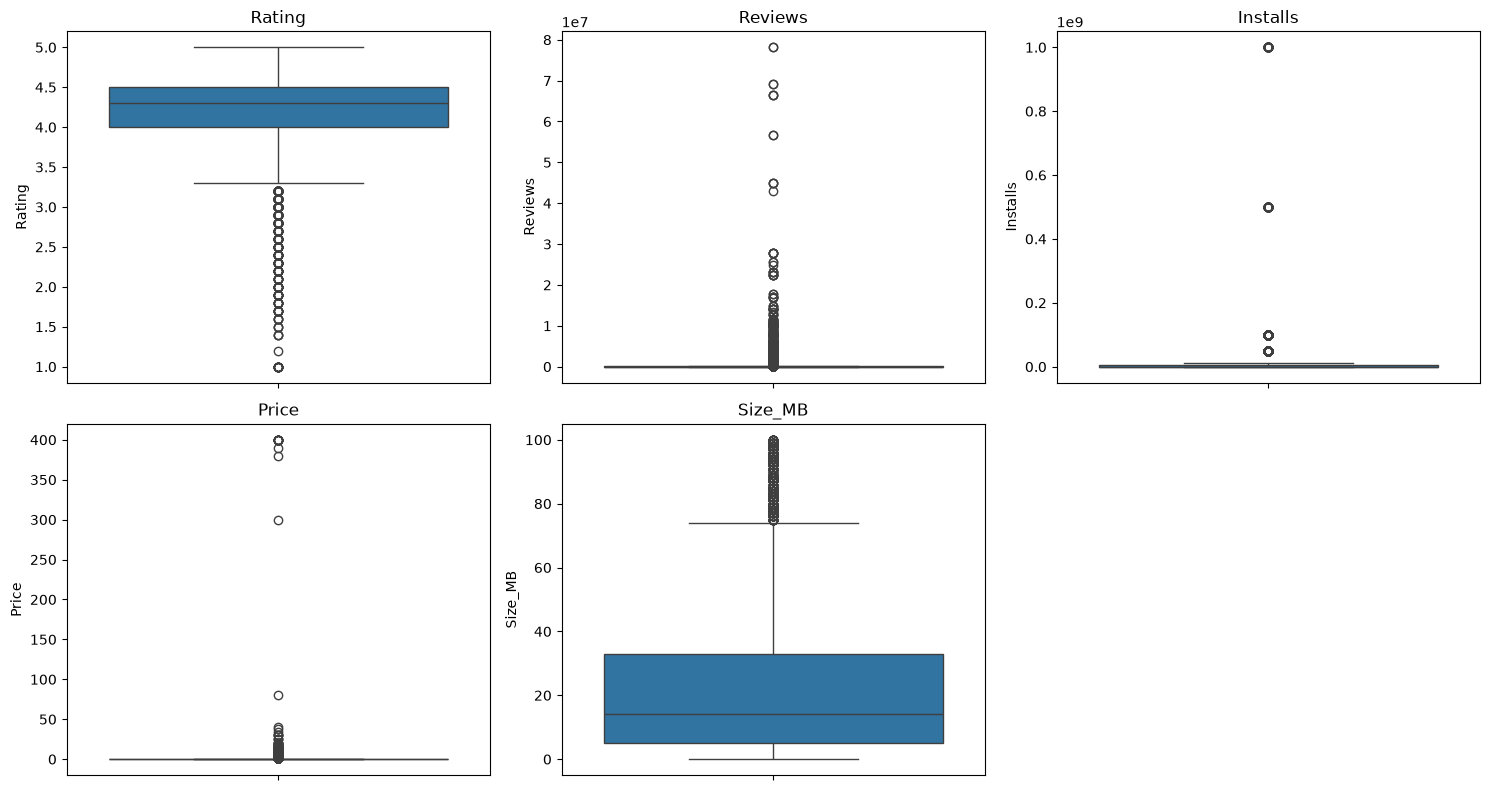

In [42]:

numeric_columns = [
    "Rating",
    "Reviews",
    "Installs",
    "Price",
    "Size_MB"
]

plt.figure(figsize=(15, 8))

for i, column in enumerate(numeric_columns):

    plt.subplot(2, 3, i + 1)

    sns.boxplot(
        y=data[column]
    )

    plt.title(column)

plt.tight_layout()

plt.show()

In [43]:

print("Skewness of numerical features:\n")

for column in [
    "Reviews",
    "Installs",
    "Price",
    "Size_MB"
]:

    print(
        column,
        ":",
        round(data[column].skew(), 3)
    )

Skewness of numerical features:

Reviews : 16.208
Installs : 9.376
Price : 23.951
Size_MB : 1.441


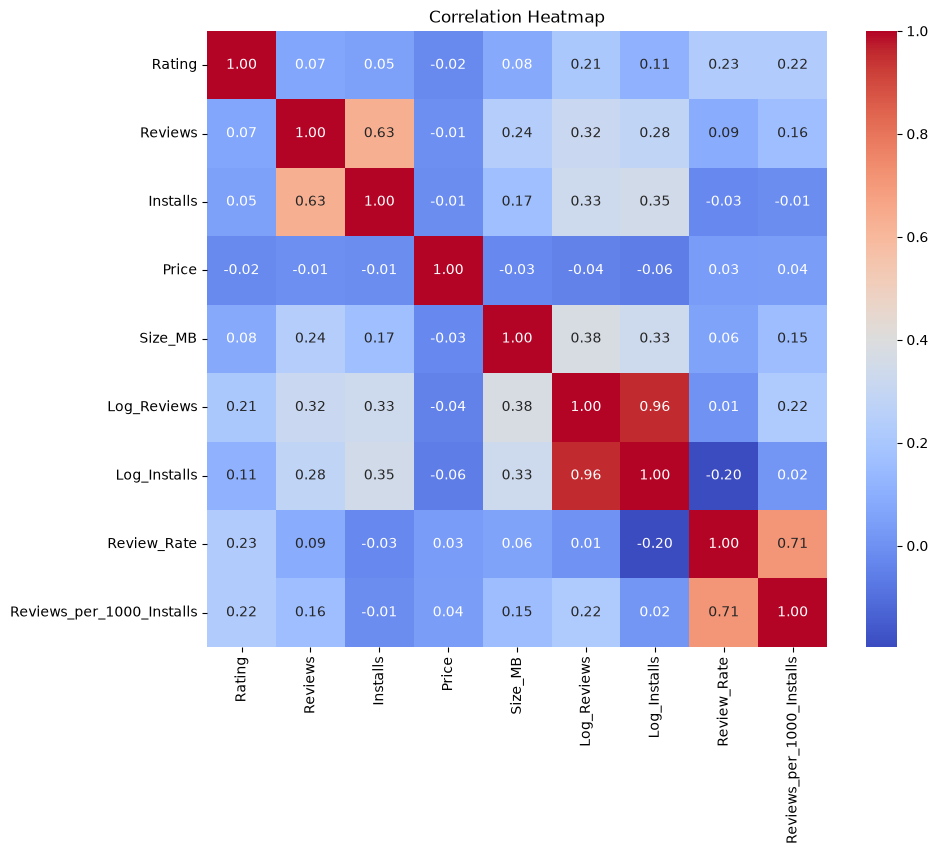

In [44]:

correlation_columns = [
    "Rating",
    "Reviews",
    "Installs",
    "Price",
    "Size_MB",
    "Log_Reviews",
    "Log_Installs",
    "Review_Rate",
    "Reviews_per_1000_Installs"
]

correlation_matrix = (
    data[correlation_columns]
    .corr()
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [45]:

features = [
    "Category",
    "Reviews",
    "Size_MB",
    "Installs",
    "Type",
    "Price",
    "Content Rating",
    "Genres",
    "Updated_Year",
    "Updated_Month",
    "Updated_Day",
    "Current Ver",
    "Android Ver",
    "Log_Reviews",
    "Log_Installs",
    "Review_Rate",
    "Smoothed_Review_Rate",
    "Reviews_per_1000_Installs",
    "Log_Size"
]

X = data[features].copy()
y = data["Rating"].copy()

print("Number of input features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)

Number of input features: 19
X shape: (8892, 19)
y shape: (8892,)


In [46]:

numeric_features = [
    "Reviews",
    "Size_MB",
    "Installs",
    "Price",
    "Updated_Year",
    "Updated_Month",
    "Updated_Day",
    "Log_Reviews",
    "Log_Installs",
    "Review_Rate",
    "Smoothed_Review_Rate",
    "Reviews_per_1000_Installs",
    "Log_Size"
]

print("Numerical Features:")
for feature in numeric_features:
    print("-", feature)

Numerical Features:
- Reviews
- Size_MB
- Installs
- Price
- Updated_Year
- Updated_Month
- Updated_Day
- Log_Reviews
- Log_Installs
- Review_Rate
- Smoothed_Review_Rate
- Reviews_per_1000_Installs
- Log_Size


In [47]:

categorical_features = [
    "Category",
    "Type",
    "Content Rating",
    "Genres",
    "Current Ver",
    "Android Ver"
]

print("Categorical Features:")
for feature in categorical_features:
    print("-", feature)

Categorical Features:
- Category
- Type
- Content Rating
- Genres
- Current Ver
- Android Ver


In [48]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=" * 60)
print("TRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTESTING DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("=" * 60)

TRAINING DATA
X_train: (7113, 19)
y_train: (7113,)

TESTING DATA
X_test: (1779, 19)
y_test: (1779,)


In [49]:

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print("Numerical preprocessing ready.")

Numerical preprocessing ready.


In [50]:

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            )
        )
    ]
)

print("Categorical preprocessing ready.")

Categorical preprocessing ready.


In [51]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Complete preprocessing pipeline created!")

Complete preprocessing pipeline created!


In [52]:

polynomial_features = [
    "Log_Reviews",
    "Log_Installs",
    "Review_Rate",
    "Smoothed_Review_Rate",
    "Log_Size",
    "Price"
]

polynomial_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

polynomial_preprocessor = ColumnTransformer(
    transformers=[
        (
            "poly_num",
            polynomial_numeric_transformer,
            polynomial_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Fast Polynomial Regression preprocessing created!")
print("Polynomial numeric features:", polynomial_features)

Fast Polynomial Regression preprocessing created!
Polynomial numeric features: ['Log_Reviews', 'Log_Installs', 'Review_Rate', 'Smoothed_Review_Rate', 'Log_Size', 'Price']


In [53]:

models = {

    "Linear Regression":
        LinearRegression(),

    # Multiple Linear Regression uses all selected features.
    "Multiple Linear Regression":
        LinearRegression(),

    # Polynomial Regression uses degree-2 features.
    "Polynomial Regression":
        LinearRegression(),

    # Regularized linear regression.
    "Ridge Regression":
        Ridge(alpha=50.0),

    # A controlled tree helps reduce overfitting.
    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=5,
            random_state=42
        )
}

print("Models created:\n")

for name in models:
    print("✓", name)

Models created:

✓ Linear Regression
✓ Multiple Linear Regression
✓ Polynomial Regression
✓ Ridge Regression
✓ Decision Tree


In [54]:
trained_models = {}

linear_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            ["Log_Reviews"]
        )
    ]
)

print("=" * 70)
print("MODEL TRAINING")
print("=" * 70)

for name, model in models.items():

    print("\nTraining:", name)

    if name == "Linear Regression":
        current_preprocessor = linear_preprocessor

    elif name == "Polynomial Regression":
        current_preprocessor = polynomial_preprocessor

    else:
        current_preprocessor = preprocessor

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                current_preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    trained_models[name] = pipeline

    print("✓", name, "trained successfully!")

print("\n" + "=" * 70)
print("ALL 5 MODELS TRAINED SUCCESSFULLY")
print("=" * 70)

MODEL TRAINING

Training: Linear Regression
✓ Linear Regression trained successfully!

Training: Multiple Linear Regression
✓ Multiple Linear Regression trained successfully!

Training: Polynomial Regression
✓ Polynomial Regression trained successfully!

Training: Ridge Regression
✓ Ridge Regression trained successfully!

Training: Decision Tree
✓ Decision Tree trained successfully!

ALL 5 MODELS TRAINED SUCCESSFULLY


In [55]:
results = []

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(results_df)
results_df["Approx. Accuracy (%)"] = (
    100 - (results_df["MAE"] / 5 * 100)
).clip(0, 100)

display(
    results_df[
        [
            "Model",
            "MAE",
            "RMSE",
            "R2 Score",
            "Approx. Accuracy (%)"
        ]
    ]
)

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,0.322371,0.472409,0.151710
1,Multiple Linear Regression,0.331647,0.481966,0.117040
2,Polynomial Regression,0.334734,0.486264,0.101222
3,Decision Tree,0.349778,0.532688,-0.078583
4,Linear Regression,0.354010,0.508291,0.017954


,Model,MAE,RMSE,R2 Score,Approx. Accuracy (%)
0,Ridge Regression,0.322371,0.472409,0.151710,93.552590
1,Multiple Linear Regression,0.331647,0.481966,0.117040,93.367065
2,Polynomial Regression,0.334734,0.486264,0.101222,93.305328
3,Decision Tree,0.349778,0.532688,-0.078583,93.004435
4,Linear Regression,0.354010,0.508291,0.017954,92.919796


In [56]:

comparison = results_df.copy()

display(comparison)

,Model,MAE,RMSE,R2 Score,Approx. Accuracy (%)
0,Ridge Regression,0.322371,0.472409,0.151710,93.552590
1,Multiple Linear Regression,0.331647,0.481966,0.117040,93.367065
2,Polynomial Regression,0.334734,0.486264,0.101222,93.305328
3,Decision Tree,0.349778,0.532688,-0.078583,93.004435
4,Linear Regression,0.354010,0.508291,0.017954,92.919796


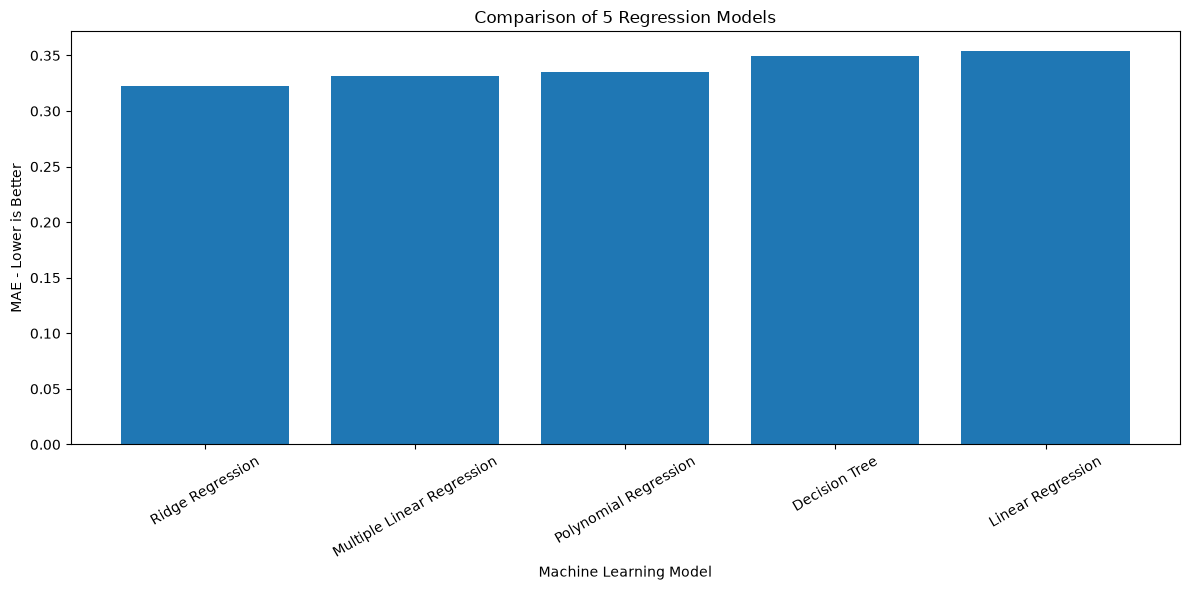

In [57]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("MAE - Lower is Better")
plt.title("Comparison of 5 Regression Models")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [58]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_row = results_df.iloc[0]

print("=" * 60)
print("BEST MODEL")
print("=" * 60)

print("Model :", best_model_name)
print("MAE   :", round(best_row["MAE"], 4))
print("RMSE  :", round(best_row["RMSE"], 4))
print("R2    :", round(best_row["R2 Score"], 4))
print("Approx. Accuracy (%):", round(
    best_row["Approx. Accuracy (%)"], 2
))
joblib.dump(
    best_model,
    "best_google_play_rating_model.pkl"
)

print("\nBest model saved as:")
print("best_google_play_rating_model.pkl")

BEST MODEL
Model : Ridge Regression
MAE   : 0.3224
RMSE  : 0.4724
R2    : 0.1517
Approx. Accuracy (%): 93.55

Best model saved as:
best_google_play_rating_model.pkl


In [59]:
reviews = 9941
installs = 1000000
size_mb = np.nan

review_rate = reviews / installs if installs > 0 else np.nan

smoothed_review_rate = (
    reviews +
    smoothing_strength * global_review_rate
) / (
    installs +
    smoothing_strength
)

reviews_per_1000 = smoothed_review_rate * 1000

new_app = pd.DataFrame({

    "Category": ["ENTERTAINMENT"],
    "Reviews": [reviews],
    "Size_MB": [size_mb],
    "Installs": [installs],

    "Type": ["Free"],
    "Price": [0.0],

    "Content Rating": ["Teen"],
    "Genres": ["Entertainment"],

    "Updated_Year": [2017],
    "Updated_Month": [7],
    "Updated_Day": [7],

    "Current Ver": ["varies with device"],
    "Android Ver": ["varies with device"],

    "Log_Reviews": [np.log1p(reviews)],
    "Log_Installs": [np.log1p(installs)],

    "Review_Rate": [review_rate],
    "Smoothed_Review_Rate": [smoothed_review_rate],
    "Reviews_per_1000_Installs": [reviews_per_1000],

    "Log_Size": [
        np.log1p(size_mb) if pd.notna(size_mb) else np.nan
    ]
})
prediction = best_model.predict(new_app)[0]
prediction = np.clip(
    prediction,
    1.0,
    5.0
)

print("=" * 60)
print("NEW APP RATING PREDICTION")
print("=" * 60)

print("Category :", new_app["Category"].iloc[0])
print("Reviews  :", reviews)
print("Installs :", installs)
print("Price    :", new_app["Price"].iloc[0])
print("Best Model Used :", best_model_name)

print("\nPredicted Rating:", round(prediction, 2), "/ 5")

NEW APP RATING PREDICTION
Category : ENTERTAINMENT
Reviews  : 9941
Installs : 1000000
Price    : 0.0
Best Model Used : Ridge Regression

Predicted Rating: 3.99 / 5
